# **REGRESSÃO LOGÍSTICA MULTINOMIAL**



### **Configuração da pasta raiz**

In [1]:
import sys
import os

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))

# Adiciona a raiz do projeto ao path do Python para que as importações funcionem
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)



### **Bibliotecas**

In [1]:
import pandas as pd
import numpy as np                      
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import OneHotEncoder, StandardScaler              
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, balanced_accuracy_score
from sklearn.metrics import roc_auc_score, roc_curve,auc as sklearn_auc
from sklearn.model_selection import train_test_split

### **Leitura da base de dados**

In [3]:
FILES = {
    'final': "data/00_final_dataset.csv"
}

In [4]:
dfs = {}

for key, filename in FILES.items():
    file_path = f'../{filename}'
    
    try:
        dfs[key] = pd.read_csv(file_path)
        
        print(f"✅ {key.ljust(15)}: Carregado ({len(dfs[key])} linhas)")
        
    except FileNotFoundError:
        print(f"❌ {key.ljust(15)}: Arquivo não encontrado em '{file_path}'")
    except Exception as e:
        print(f"❌ {key.ljust(15)}: Erro - {e}")

✅ final          : Carregado (954 linhas)


In [5]:
dados = dfs['final'].copy()

### **Especificando variáveis explicativas e variável resposta**

*Lista de nomes das variáveis explicativas, separando em quantitativas e qualitativas*

In [6]:
# Variáveis explicativas quantitativas
lista_X_quanti = [
  # Informações Físicas e do Draft
    'draft_year', 
    'draft_age', 
    'years_college', 
    'mock_pick',        # Expectativa do mercado antes do draft
    'height_cm', 
    'weight_kg',

    # Estatísticas Avançadas (Eficiência)
    'true_shooting_pct', 
    'effective_field_goal_pct', 
    'usage_pct',
    'offensive_win_shares', 
    'defensive_win_shares', 
    'win_shares_per_40min',
    'three_point_attempt_rate', 
    'free_throw_attempt_rate',

    # Estatísticas de Arremesso (Volume e Precisão)
    'field_goal_attempted', 
    'three_pointers_made', 
    'three_pointers_attempted', 
    'three_point_pct',
    'free_throw_attempted', 
    'free_throw_pct',

    # Estatísticas tradicionais (por 40 minutos)
    'points', 
    'assists', 
    'total_rebounds', 
    'offensive_rebounds', 
    'defensive_rebounds',
    'steals', 
    'blocks', 
    'turnovers', 
    'personal_fouls',

    # Experiência no College (Acumulados)
    'career_games', 
    'career_starts', 
    'career_minutes', 
    'career_awards_count'
]

# Variáveis explicativas qualitativas
lista_X_quali = [
    'college_name', 
    'conference', 
    'position'
]

In [7]:
ordem_categorias = ['Bust', 'Rotation', 'Starter', 'Star']

In [8]:
def comparar_colunas(df1, df2):
    colunas_tabela1 = set(df1.columns)
    colunas_tabela2 = set(df2.columns)

    apenas_na_tabela1 = colunas_tabela1 - colunas_tabela2
    apenas_na_tabela2 = colunas_tabela2 - colunas_tabela1
    diferentes_nas_duas = colunas_tabela1.symmetric_difference(colunas_tabela2)

    print(f"Colunas que só existem na Tabela 1: {apenas_na_tabela1}")
    print(f"Colunas que só existem na Tabela 2: {apenas_na_tabela2}")
    print(f"---")
    print(f"Todas as colunas que não dão 'match': {diferentes_nas_duas}")

In [9]:
def mostrar_pvalor_medio(modelo, corte):
    p_valores_matriz = modelo.pvalues

    # 2. Calcular a média dos p-valores entre as categorias (ao longo das colunas)
    p_valor_medio = p_valores_matriz.mean(axis=1)

    # 3. Criar um DataFrame para organizar a exibição
    tabela_p_valores = pd.DataFrame({
        'Variável': p_valor_medio.index,
        'P-Valor Médio': p_valor_medio.values
    })

    # 4. Ordenar de forma decrescente (do menos significativo para o mais significativo)
    tabela_p_valores = tabela_p_valores.sort_values(by='P-Valor Médio', ascending=False)
    vars_para_remover = tabela_p_valores[tabela_p_valores['P-Valor Médio'] > corte]['Variável'].tolist()
    tabela_p_valores['P-Valor Médio'] = tabela_p_valores['P-Valor Médio'].apply(lambda x: f'{x:.4f}')

    # 5. Imprimir a tabela formatada
    print("Tabela de Significância (P-Valor Médio por Variável):")
    print(tabela_p_valores.to_string(index=False))

    print(f"\nVariáveis sugeridas para exclusão (P-Valor > {corte}):\n{vars_para_remover}")

In [10]:
def mostrar_pvalor(modelo, corte):
    p_valores_matriz = modelo.pvalues

    # 2. Calcular o MÍNIMO dos p-valores entre as categorias (ao longo das colunas)
    p_valor_minimo = p_valores_matriz.min(axis=1)

    # 3. Criar um DataFrame para organizar a exibição
    tabela_p_valores = pd.DataFrame({
        'Variável': p_valor_minimo.index,
        'P-Valor Mínimo': p_valor_minimo.values
    })

    # 4. Ordenar de forma decrescente (do menos significativo para o mais significativo)
    tabela_p_valores = tabela_p_valores.sort_values(by='P-Valor Mínimo', ascending=False)
    
    # Filtra as variáveis pelo menor p-valor entre as classes.
    vars_para_remover = tabela_p_valores[tabela_p_valores['P-Valor Mínimo'] > corte]['Variável'].tolist()

    # Formata os valores para exibição.
    tabela_p_valores['P-Valor Mínimo'] = tabela_p_valores['P-Valor Mínimo'].apply(lambda x: f'{x:.4f}')

    # 5. Imprimir a tabela formatada
    print("Tabela de Significância (Melhor P-Valor atingido por Variável):")
    print(tabela_p_valores.to_string(index=False))

    print(f"\nVariáveis sugeridas para exclusão (NENHUM P-Valor < {corte}):\n{vars_para_remover}")

### **Etapa 2: Pré-processamento de variáveis explicativas**

*Codificação one-hot para variáveis qualitativas*

In [11]:
# Criando um objeto da classe OneHotEncoder (dropando a primeira categoria de cada variável)
codificador_one_hot = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')

# Criando as variáveis dummies e salvando em um objeto à parte
aux_dummies = codificador_one_hot.fit_transform(dados[lista_X_quali])

# Criando nomes para as variáveis dummies
col_names = codificador_one_hot.get_feature_names_out(lista_X_quali)

# Transformando o novo objeto criado em um DataFrame
aux_dummies = pd.DataFrame(aux_dummies, columns=col_names, index=dados.index)

*Criação de objetos para explicativas (X) e resposta (y)*

In [12]:
X = pd.concat([dados[lista_X_quanti], aux_dummies], axis=1)
y = dados['target_label']

*Padronizar apenas as colunas numéricas*

In [13]:
scaler = StandardScaler()
cols_num = X.select_dtypes(include=['float64', 'int64']).columns
X_scaled = X.copy()
X_scaled[cols_num] = scaler.fit_transform(X[cols_num])

X_final = sm.add_constant(X_scaled)

### **Etapa 3: Modelo de regressão logística multinomial**

In [14]:

X_treino, X_teste, y_treino, y_teste = train_test_split(X_final, y,
                                                        test_size=0.2,
                                                        stratify=y,
                                                        random_state=123)

*Ajuste do modelo 1*

In [15]:
modelo_v1 = sm.MNLogit(y_treino, X_treino).fit_regularized(method='l1', alpha=1.0)
print(modelo_v1.summary())

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.8740483812780301
            Iterations: 381
            Function evaluations: 381
            Gradient evaluations: 381
                          MNLogit Regression Results                          
Dep. Variable:           target_label   No. Observations:                  763
Model:                        MNLogit   Df Residuals:                      613
Method:                           MLE   Df Model:                          147
Date:                Tue, 03 Mar 2026   Pseudo R-squ.:                  0.2742
Time:                        15:24:40   Log-Likelihood:                -625.13
converged:                       True   LL-Null:                       -861.25
Covariance Type:            nonrobust   LLR p-value:                 8.837e-36
      target_label=Rotation       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------

*Limpeza do modelo 1*

In [16]:
df_coefs = modelo_v1.params
variaveis_selecionadas = df_coefs[(df_coefs.T != 0).any()]
# Pegar os nomes das colunas que sobreviveram (exceto a constante)
colunas_vivas = [col for col in variaveis_selecionadas.index if col != 'const']

X_modelo_v1 = X_treino[colunas_vivas]


In [17]:
comparar_colunas(X_treino, X_modelo_v1)

Colunas que só existem na Tabela 1: {'const', 'free_throw_attempt_rate', 'conference_WCC', 'offensive_rebounds'}
Colunas que só existem na Tabela 2: set()
---
Todas as colunas que não dão 'match': {'const', 'offensive_rebounds', 'conference_WCC', 'free_throw_attempt_rate'}


*Ajuste do modelo 2*

In [18]:
# Ajusta o modelo reduzido com regularização L1.
modelo_v2 = sm.MNLogit(y_treino, sm.add_constant(X_modelo_v1)).fit_regularized(method='l1', alpha=1.0)
print(modelo_v2.summary())

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.8740483817648506
            Iterations: 371
            Function evaluations: 372
            Gradient evaluations: 371
                          MNLogit Regression Results                          
Dep. Variable:           target_label   No. Observations:                  763
Model:                        MNLogit   Df Residuals:                      613
Method:                           MLE   Df Model:                          147
Date:                Tue, 03 Mar 2026   Pseudo R-squ.:                  0.2742
Time:                        15:25:25   Log-Likelihood:                -625.13
converged:                       True   LL-Null:                       -861.25
Covariance Type:            nonrobust   LLR p-value:                 8.828e-36
      target_label=Rotation       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------

In [19]:
mostrar_pvalor(modelo_v2, 0.50)

Tabela de Significância (Melhor P-Valor atingido por Variável):
                   Variável P-Valor Mínimo
          true_shooting_pct         0.9319
             position_Guard         0.7903
   three_pointers_attempted         0.7338
        three_pointers_made         0.7260
             career_minutes         0.7078
          college_name_Duke         0.6925
            conference_CUSA         0.6194
       college_name_Gonzaga         0.5704
       field_goal_attempted         0.5658
             total_rebounds         0.5527
 college_name_Small_College         0.4989
               career_games         0.4972
    college_name_Washington         0.4925
         college_name_UConn         0.4687
           college_name_UNC         0.4660
        college_name_Kansas         0.4438
        conference_Big East         0.4121
      college_name_Michigan         0.4113
      college_name_Maryland         0.3898
 college_name_Florida State         0.3843
             conference_SEC      

*Limpeza do modelo 2*

In [20]:
colunas_para_remover = ['true_shooting_pct', 'position_Guard', 'three_pointers_attempted', 'three_pointers_made', 'career_minutes', 'college_name_Duke', 'conference_CUSA', 'college_name_Gonzaga', 'field_goal_attempted', 'total_rebounds']


X_modelo_v2 = X_modelo_v1.drop(columns=colunas_para_remover)

In [21]:
comparar_colunas(X_modelo_v1, X_modelo_v2)

Colunas que só existem na Tabela 1: {'college_name_Gonzaga', 'college_name_Duke', 'true_shooting_pct', 'career_minutes', 'field_goal_attempted', 'three_pointers_made', 'conference_CUSA', 'position_Guard', 'three_pointers_attempted', 'total_rebounds'}
Colunas que só existem na Tabela 2: set()
---
Todas as colunas que não dão 'match': {'college_name_Duke', 'true_shooting_pct', 'three_pointers_made', 'conference_CUSA', 'total_rebounds', 'three_pointers_attempted', 'position_Guard', 'college_name_Gonzaga', 'career_minutes', 'field_goal_attempted'}


*Ajuste no modelo 3*

In [22]:
modelo_v3 = sm.MNLogit(y_treino, sm.add_constant(X_modelo_v2)).fit_regularized(method='l1', alpha=1.0)
print(modelo_v3.summary())

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.8771362204094849
            Iterations: 225
            Function evaluations: 226
            Gradient evaluations: 225
                          MNLogit Regression Results                          
Dep. Variable:           target_label   No. Observations:                  763
Model:                        MNLogit   Df Residuals:                      624
Method:                           MLE   Df Model:                          136
Date:                Tue, 03 Mar 2026   Pseudo R-squ.:                  0.2692
Time:                        15:25:39   Log-Likelihood:                -629.42
converged:                       True   LL-Null:                       -861.25
Covariance Type:            nonrobust   LLR p-value:                 2.337e-37
      target_label=Rotation       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------

*Limpeza do modelo 3*

In [23]:
mostrar_pvalor(modelo_v3, 0.25)

Tabela de Significância (Melhor P-Valor atingido por Variável):
                   Variável P-Valor Mínimo
 college_name_Small_College         0.6916
               career_games         0.5750
           college_name_UNC         0.5241
         college_name_UConn         0.5066
             conference_SEC         0.5053
    college_name_Washington         0.4574
      college_name_Michigan         0.4305
      college_name_Maryland         0.3839
                     blocks         0.3661
 college_name_Florida State         0.3611
    college_name_Ohio State         0.3582
        college_name_Kansas         0.3551
        conference_Big East         0.3322
       defensive_win_shares         0.3162
           college_name_USC         0.3055
       college_name_Florida         0.3013
        college_name_Oregon         0.2904
          conference_Pac-12         0.2899
          conference_Big 12         0.2820
                     points         0.2771
      college_name_Syracuse      

In [24]:
colunas_para_remover_v2 = ['college_name_Small_College', 'career_games', 'college_name_UNC', 'college_name_UConn', 'conference_SEC', 'college_name_Washington', 'college_name_Michigan', 'college_name_Maryland', 'blocks', 'college_name_Florida State', 'college_name_Ohio State', 'college_name_Kansas', 'conference_Big East', 'defensive_win_shares', 'college_name_USC', 'college_name_Florida', 'college_name_Oregon', 'conference_Pac-12', 'conference_Big 12', 'points', 'college_name_Syracuse']

X_modelo_v3 = X_modelo_v2.drop(columns=[c for c in colunas_para_remover_v2 if c in X_modelo_v2.columns])

*Ajuste no modelo 4*

In [25]:
modelo_v4 = sm.MNLogit(y_treino, sm.add_constant(X_modelo_v3)).fit()
print(modelo_v4.summary())

         Current function value: 0.857410
         Iterations: 35
                          MNLogit Regression Results                          
Dep. Variable:           target_label   No. Observations:                  763
Model:                        MNLogit   Df Residuals:                      667
Method:                           MLE   Df Model:                           93
Date:                Tue, 03 Mar 2026   Pseudo R-squ.:                  0.2404
Time:                        15:25:39   Log-Likelihood:                -654.20
converged:                      False   LL-Null:                       -861.25
Covariance Type:            nonrobust   LLR p-value:                 4.574e-42
      target_label=Rotation       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                          -0.5334      0.096     -5.552      0.000      -0.722      -0.345
draft_year    

c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


*Limpeza do modelo 4*

In [26]:
mostrar_pvalor(modelo_v4, 0.10)

Tabela de Significância (Melhor P-Valor atingido por Variável):
                   Variável P-Valor Mínimo
college_name_Michigan State         0.5941
       win_shares_per_40min         0.5190
         conference_Big Ten         0.2879
             free_throw_pct         0.2187
                  usage_pct         0.1638
              career_starts         0.1489
                  weight_kg         0.1194
      college_name_Stanford         0.1055
                  turnovers         0.0677
         college_name_Texas         0.0615
                 draft_year         0.0608
       offensive_win_shares         0.0442
              years_college         0.0423
          college_name_UCLA         0.0421
   three_point_attempt_rate         0.0388
            three_point_pct         0.0321
                  height_cm         0.0248
       free_throw_attempted         0.0230
           position_Forward         0.0218
        career_awards_count         0.0193
conference_Small_Conference      

In [27]:
colunas_para_remover_v3 = ['college_name_Michigan State', 'win_shares_per_40min', 'conference_Big Ten', 'free_throw_pct', 'usage_pct', 'career_starts', 'weight_kg', 'college_name_Stanford']


X_modelo_v4 = X_modelo_v3.drop(columns=[c for c in colunas_para_remover_v3 if c in X_modelo_v3.columns])

*Ajuste no modelo 5*

In [28]:
modelo_v5 = sm.MNLogit(y_treino, sm.add_constant(X_modelo_v4)).fit()
print(modelo_v5.summary())

Optimization terminated successfully.
         Current function value: 0.877801
         Iterations 9
                          MNLogit Regression Results                          
Dep. Variable:           target_label   No. Observations:                  763
Model:                        MNLogit   Df Residuals:                      691
Method:                           MLE   Df Model:                           69
Date:                Tue, 03 Mar 2026   Pseudo R-squ.:                  0.2223
Time:                        15:25:40   Log-Likelihood:                -669.76
converged:                       True   LL-Null:                       -861.25
Covariance Type:            nonrobust   LLR p-value:                 4.667e-45
      target_label=Rotation       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                          -0.5227      0.095     -5.497      0.000   

*Limpeza do modelo 5*

In [29]:
mostrar_pvalor(modelo_v5, 0.05)

Tabela de Significância (Melhor P-Valor atingido por Variável):
                   Variável P-Valor Mínimo
         college_name_Texas         0.1197
              years_college         0.1173
       free_throw_attempted         0.1032
          college_name_UCLA         0.0921
                  turnovers         0.0797
   three_point_attempt_rate         0.0579
conference_Small_Conference         0.0460
            three_point_pct         0.0417
        career_awards_count         0.0359
                  height_cm         0.0326
           position_Forward         0.0317
             conference_MWC         0.0247
                 draft_year         0.0221
       offensive_win_shares         0.0174
                  draft_age         0.0104
             personal_fouls         0.0035
          conference_Pac-10         0.0013
         defensive_rebounds         0.0005
   effective_field_goal_pct         0.0004
                    assists         0.0004
      college_name_Kentucky      

In [30]:
# 1. Lista de colunas para remoção de RUÍDO (P-Value alto em todas as classes)
colunas_para_remover_v4 = ['college_name_Texas', 'years_college', 'free_throw_attempted', 'college_name_UCLA', 'turnovers', 'three_point_attempt_rate']


# 2. Filtrar o dataset (partindo do X_modelo_v4)
X_modelo_v5 = X_modelo_v4.drop(columns=[c for c in colunas_para_remover_v4 if c in X_modelo_v4.columns])

*Ajuste do modelo 6*

In [31]:
modelo_v6 = sm.MNLogit(y_treino, sm.add_constant(X_modelo_v5)).fit()
print(modelo_v6.summary())

Optimization terminated successfully.
         Current function value: 0.896165
         Iterations 9
                          MNLogit Regression Results                          
Dep. Variable:           target_label   No. Observations:                  763
Model:                        MNLogit   Df Residuals:                      709
Method:                           MLE   Df Model:                           51
Date:                Tue, 03 Mar 2026   Pseudo R-squ.:                  0.2061
Time:                        15:25:40   Log-Likelihood:                -683.77
converged:                       True   LL-Null:                       -861.25
Covariance Type:            nonrobust   LLR p-value:                 3.989e-47
      target_label=Rotation       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                          -0.5185      0.094     -5.517      0.000   

*Limpeza do modelo 6*

In [32]:
mostrar_pvalor(modelo_v6, 0.05)

Tabela de Significância (Melhor P-Valor atingido por Variável):
                   Variável P-Valor Mínimo
            three_point_pct         0.1516
                  height_cm         0.0560
                 draft_year         0.0358
           position_Forward         0.0271
        career_awards_count         0.0246
       offensive_win_shares         0.0242
conference_Small_Conference         0.0213
             conference_MWC         0.0188
         defensive_rebounds         0.0079
                  draft_age         0.0041
                    assists         0.0008
          conference_Pac-10         0.0006
             personal_fouls         0.0005
   effective_field_goal_pct         0.0001
      college_name_Kentucky         0.0000
                  mock_pick         0.0000
                     steals         0.0000
                      const         0.0000

Variáveis sugeridas para exclusão (NENHUM P-Valor < 0.05):
['three_point_pct', 'height_cm']


In [33]:
# 1. Lista de colunas para remoção de RUÍDO (P-Value alto em todas as classes)
colunas_para_remover_v5 = ['three_point_pct', 'height_cm']


# 2. Filtrar o dataset (partindo do X_modelo_v5)
X_modelo_v6 = X_modelo_v5.drop(columns=[c for c in colunas_para_remover_v5 if c in X_modelo_v5.columns])

In [34]:
modelo_v7 = sm.MNLogit(y_treino, sm.add_constant(X_modelo_v6)).fit()
print(modelo_v7.summary())

Optimization terminated successfully.
         Current function value: 0.901375
         Iterations 9
                          MNLogit Regression Results                          
Dep. Variable:           target_label   No. Observations:                  763
Model:                        MNLogit   Df Residuals:                      715
Method:                           MLE   Df Model:                           45
Date:                Tue, 03 Mar 2026   Pseudo R-squ.:                  0.2015
Time:                        15:25:40   Log-Likelihood:                -687.75
converged:                       True   LL-Null:                       -861.25
Covariance Type:            nonrobust   LLR p-value:                 2.976e-48
      target_label=Rotation       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                          -0.5159      0.093     -5.519      0.000   

In [35]:
mostrar_pvalor(modelo_v7, 0.05)

Tabela de Significância (Melhor P-Valor atingido por Variável):
                   Variável P-Valor Mínimo
                 draft_year         0.0325
           position_Forward         0.0308
       offensive_win_shares         0.0247
        career_awards_count         0.0227
             conference_MWC         0.0198
conference_Small_Conference         0.0171
                  draft_age         0.0043
         defensive_rebounds         0.0010
             personal_fouls         0.0010
          conference_Pac-10         0.0005
                    assists         0.0005
   effective_field_goal_pct         0.0001
      college_name_Kentucky         0.0000
                  mock_pick         0.0000
                     steals         0.0000
                      const         0.0000

Variáveis sugeridas para exclusão (NENHUM P-Valor < 0.05):
[]


In [36]:
mostrar_pvalor_medio(modelo_v7, 0.05)

Tabela de Significância (P-Valor Médio por Variável):
                   Variável P-Valor Médio
                 draft_year        0.4892
       offensive_win_shares        0.3455
             conference_MWC        0.3142
        career_awards_count        0.2404
conference_Small_Conference        0.2288
           position_Forward        0.2121
                    assists        0.1831
      college_name_Kentucky        0.1229
   effective_field_goal_pct        0.0438
          conference_Pac-10        0.0275
                  draft_age        0.0187
             personal_fouls        0.0163
         defensive_rebounds        0.0071
                  mock_pick        0.0006
                     steals        0.0002
                      const        0.0000

Variáveis sugeridas para exclusão (P-Valor > 0.05):
['draft_year', 'offensive_win_shares', 'conference_MWC', 'career_awards_count', 'conference_Small_Conference', 'position_Forward', 'assists', 'college_name_Kentucky']


*Modelo Final*

In [37]:
modelo = modelo_v7

*Avaliação de colinearidade no modelo*

In [38]:
vif = pd.DataFrame({
    "Variável": modelo.model.exog_names,
    "VIF": [variance_inflation_factor(modelo.model.exog, i) for i in range(modelo.model.exog.shape[1])]
})

print(vif)

                       Variável       VIF
0                         const  1.007524
1                    draft_year  1.257343
2                     draft_age  1.735347
3                     mock_pick  1.659971
4      effective_field_goal_pct  1.656047
5          offensive_win_shares  1.880602
6                       assists  1.872149
7            defensive_rebounds  1.767218
8                        steals  1.343044
9                personal_fouls  1.595222
10          career_awards_count  1.241777
11        college_name_Kentucky  1.068351
12               conference_MWC  1.053731
13            conference_Pac-10  1.102942
14  conference_Small_Conference  1.114565
15             position_Forward  1.403030


### **Atribuição de resposta predita**

*Escolha do modelo*

In [39]:
X_teste_alinhado = X_teste[X_modelo_v6.columns]
X_teste_final = sm.add_constant(X_teste_alinhado, has_constant='add')
p_hat_teste = modelo.predict(X_teste_final)
y_hat_teste = p_hat_teste.idxmax(axis=1)

*Aplicação do modelo na base*

In [40]:
probabilidades = p_hat_teste.copy()

# Organiza os resultados das observações do teste.
# Filtramos 'dados' apenas para as linhas que pertencem ao teste
dados_teste_final = dados.loc[X_teste_alinhado.index].copy()

# Adicionamos as probabilidades renomeando as colunas para o padrão 'Prob_Classe'
df_probs_renomeado = probabilidades.rename(columns=lambda x: f'Prob_{x}')
dados_teste_final = pd.concat([dados_teste_final, df_probs_renomeado], axis=1)

# Adicionamos a coluna de previsão
dados_teste_final['Previsao_Modelo'] = y_hat_teste


colunas_prob_reais = [c for c in dados_teste_final.columns if c.startswith('Prob_')]
colunas_vistas = ['player_name', 'target_label', 'Previsao_Modelo'] + colunas_prob_reais

mapeamento = {
    'Prob_0': 'Prob_Bust',
    'Prob_1': 'Prob_Rotation',
    'Prob_2': 'Prob_Starter',
    'Prob_3': 'Prob_Star'
}
dados_teste_final.rename(columns=mapeamento, inplace=True)

mapeamento = {i: nome for i, nome in enumerate(ordem_categorias)}

dados_teste_final['Previsao_Texto'] = dados_teste_final['Previsao_Modelo'].map(mapeamento)

colunas_vistas = ['player_name', 'target_label', 'Previsao_Texto', 'Prob_Star', 'Prob_Starter','Prob_Rotation','Prob_Bust']
display(dados_teste_final[colunas_vistas].head())

,player_name,target_label,Previsao_Texto,Prob_Star,Prob_Starter,Prob_Rotation,Prob_Bust
355,Kyle Weaver,Rotation,Rotation,0.172379,0.069832,0.477180,0.280609
521,Michael Kidd-Gilchrist,Rotation,Star,0.430757,0.409724,0.101475,0.058045
323,D.J. Strawberry,Bust,Bust,0.065796,0.001496,0.310218,0.622490
894,Terance Mann,Rotation,Bust,0.018937,0.000249,0.247093,0.733720
156,Kyle Korver,Starter,Bust,0.090328,0.002588,0.225301,0.681783


### **Análise de desempenho**

*Tabela de classificação*

In [41]:
# 1. Gerar a tabela bruta
tabela = pd.crosstab(dados_teste_final['target_label'], dados_teste_final['Previsao_Texto'])
mapeamento = {i: nome for i, nome in enumerate(ordem_categorias)}
tabela = tabela.rename(columns=mapeamento)
tabela = tabela.reindex(index=ordem_categorias, columns=ordem_categorias, fill_value=0)
display(tabela)

Previsao_Texto,Bust,Rotation,Starter,Star
target_label,,,,
Bust,82,11,5,2
Rotation,37,10,2,6
Starter,14,7,4,1
Star,5,1,1,3


In [42]:
# Tabela de classificação com frequências relativas, somando 100% em cada linha
tabela_relativa_linhas = (tabela.div(tabela.sum(axis=1), axis=0)).round(3)
tabela_relativa_linhas

Previsao_Texto,Bust,Rotation,Starter,Star
target_label,,,,
Bust,0.820,0.110,0.050,0.020
Rotation,0.673,0.182,0.036,0.109
Starter,0.538,0.269,0.154,0.038
Star,0.500,0.100,0.100,0.300


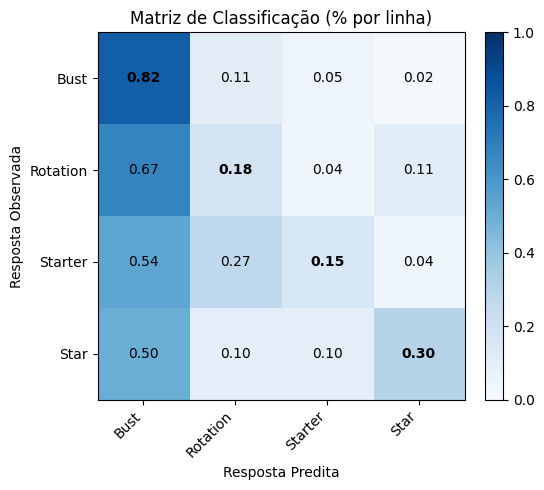

In [43]:
# Gráfico de calor com frequências relativas, somando 100% em cada linha
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_linhas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_linhas.shape[1]))
ax.set_yticks(range(tabela_relativa_linhas.shape[0]))
ax.set_xticklabels(tabela_relativa_linhas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_linhas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por linha)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [44]:
# Tabela de classificação com frequências relativas, somando 100% em cada coluna
tabela_relativa_colunas = (tabela.div(tabela.sum(axis=0), axis=1)).round(3)
tabela_relativa_colunas

Previsao_Texto,Bust,Rotation,Starter,Star
target_label,,,,
Bust,0.594,0.379,0.417,0.167
Rotation,0.268,0.345,0.167,0.500
Starter,0.101,0.241,0.333,0.083
Star,0.036,0.034,0.083,0.250


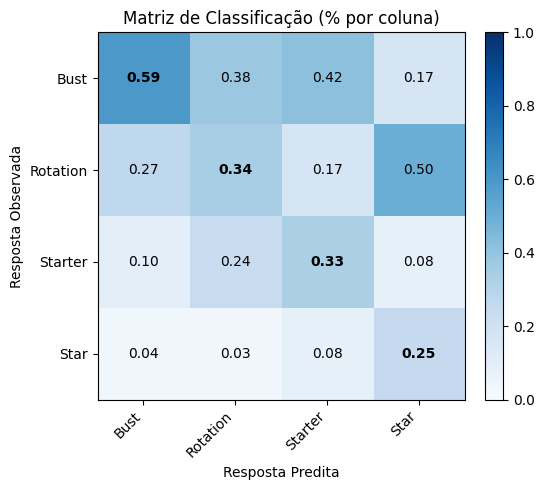

In [45]:
# Gráfico de calor com frequências relativas, somando 100% em cada coluna
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_colunas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_colunas.shape[1]))
ax.set_yticks(range(tabela_relativa_colunas.shape[0]))
ax.set_xticklabels(tabela_relativa_colunas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_colunas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por coluna)")

for (i, j), v in np.ndenumerate(tabela_relativa_colunas.values):
    same_label = tabela_relativa_colunas.index[i] == tabela_relativa_colunas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

*Desempenho: acurácia, sensibilidade, especificidade, PPV e NPV*

In [46]:

# 1. Acurácia e Relatório Padrão
acuracia = accuracy_score(dados_teste_final['target_label'], dados_teste_final['Previsao_Texto'])
acuracia_bal = balanced_accuracy_score(dados_teste_final['target_label'], dados_teste_final['Previsao_Texto'])

print(f'Acurácia Global: {acuracia:.3f}')
print(f'Acurácia Balanceada: {acuracia_bal:.3f}\n')

print("Relatório de Classificação Padrão:")
print(classification_report(dados_teste_final['target_label'], dados_teste_final['Previsao_Texto'], labels=ordem_categorias))

# 2. Matriz de Confusão (Usando os labels para garantir a ordem correta)
conf_matrix = confusion_matrix(dados_teste_final['target_label'], 
                               dados_teste_final['Previsao_Texto'], 
                               labels=ordem_categorias)

# Cálculos de matriz (One-vs-Rest)
TP = np.diag(conf_matrix)
FP = conf_matrix.sum(axis=0) - TP
FN = conf_matrix.sum(axis=1) - TP
TN = conf_matrix.sum() - (FP + FN + TP)

# Fórmulas de Performance
sensibilidade = TP / (TP + FN)  # Recall
especificidade = TN / (TN + FP)
ppv = TP / (TP + FP)            # Precision
npv = TN / (TN + FN)

tabela_metricas_completas = pd.DataFrame({
    'Sensibilidade (Recall)': sensibilidade,
    'Especificidade': especificidade,
    'Precisão (PPV)': ppv,
    'NPV': npv
}, index=ordem_categorias)

display(tabela_metricas_completas.round(3))

Acurácia Global: 0.518
Acurácia Balanceada: 0.364

Relatório de Classificação Padrão:
              precision    recall  f1-score   support

        Bust       0.59      0.82      0.69       100
    Rotation       0.34      0.18      0.24        55
     Starter       0.33      0.15      0.21        26
        Star       0.25      0.30      0.27        10

    accuracy                           0.52       191
   macro avg       0.38      0.36      0.35       191
weighted avg       0.47      0.52      0.47       191



,Sensibilidade (Recall),Especificidade,Precisão (PPV),NPV
Bust,0.820,0.385,0.594,0.660
Rotation,0.182,0.860,0.345,0.722
Starter,0.154,0.952,0.333,0.877
Star,0.300,0.950,0.250,0.961


In [47]:
for classe in ordem_categorias:
    alvo_binario_star = (dados_teste_final['target_label'] == classe).astype(int)

    # Usa a probabilidade da classe avaliada nesta iteração.
    fpr, tpr, thresholds = roc_curve(alvo_binario_star, dados_teste_final[f'Prob_{classe}'])

    ks_star = np.max(tpr - fpr)
    print(f'KS para a classe {classe}: {ks_star:.3f}')

KS para a classe Bust: 0.255
KS para a classe Rotation: 0.067
KS para a classe Starter: 0.392
KS para a classe Star: 0.380


In [48]:
# AUC
auc = roc_auc_score(dados_teste_final['target_label'], probabilidades, 
                    multi_class='ovr', 
                    average='weighted')

print(f'AUC Multinomial (Weighted OvR): {auc:.3f}')

AUC Multinomial (Weighted OvR): 0.618


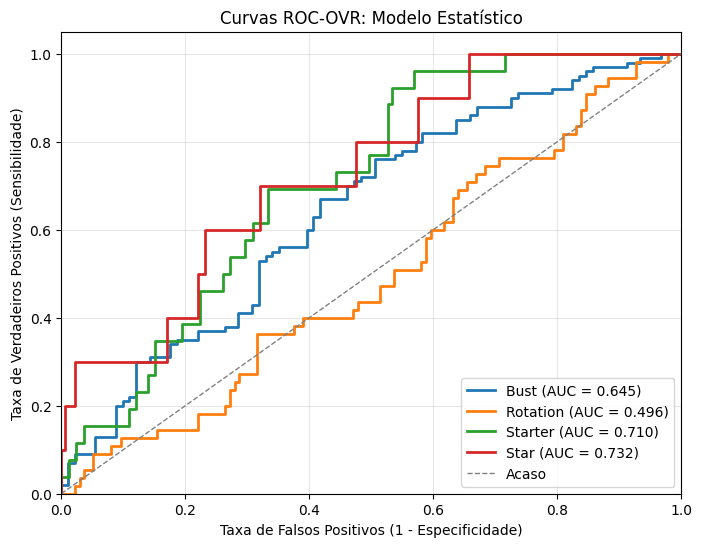

In [49]:


plt.figure(figsize=(8, 6))

for k, cls_name in enumerate(ordem_categorias):
    # 1. Criar o binário real
    y_bin = (y_teste == cls_name).astype(int)
    
    # 2. Pegar a probabilidade da classe k
    if cls_name in p_hat_teste.columns:
        prob_classe = p_hat_teste[cls_name]
    else:
        prob_classe = p_hat_teste.iloc[:, k]
    
    # 3. Calcular FPR e TPR
    fpr, tpr, _ = roc_curve(y_bin, prob_classe)
    
    # Usamos sklearn_auc explicitamente para evitar o erro de conflito
    auc_k = sklearn_auc(fpr, tpr)
    
    # 4. Plotar
    plt.plot(fpr, tpr, lw=2, label=f'{cls_name} (AUC = {auc_k:.3f})')

# Configurações do Gráfico
plt.plot([0, 1], [0, 1], '--', color='gray', lw=1, label='Acaso')
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)')
plt.ylabel('Taxa de Verdadeiros Positivos (Sensibilidade)')
plt.title('Curvas ROC-OVR: Modelo Estatístico')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

### **Mudar corte**

In [50]:
colunas_finais = modelo.model.exog_names
X_teste_final = X_teste[colunas_finais]

# 2. Gera as probabilidades na base de TESTE
probabilidades_teste = modelo.predict(X_teste_final)

# 3. Pega os nomes das classes na ordem correta
nomes_classes = sorted(y_treino.unique()) 
df_probs_teste = pd.DataFrame(probabilidades_teste.values, 
                              columns=[f'Prob_{c}' for c in nomes_classes], 
                              index=X_teste.index)

# 4. REGRA DE NEGÓCIO: AJUSTE DO PONTO DE CORTE (THRESHOLD)

previsao_teste = []

for idx, row in df_probs_teste.iterrows():
    # Classifica como Star quando a probabilidade é de pelo menos 20%.
    if row['Prob_Star'] >= 0.20:
        previsao_teste.append('Star')
        
    # Caso contrário, classifica como Starter a partir de 25%.
    elif row['Prob_Starter'] >= 0.25:
        previsao_teste.append('Starter')
        
    # Caso contrário, classifica como Rotation a partir de 30%.
    elif row['Prob_Rotation'] >= 0.30:
        previsao_teste.append('Rotation')
        
    # As demais observações recebem a classe Bust.
    else:
        previsao_teste.append('Bust')

# 5. Junta tudo num DataFrame de Resultados para avaliar
resultados_teste = pd.DataFrame({'Real': y_teste, 'Previsto': previsao_teste}, index=y_teste.index)
resultados_teste = pd.concat([resultados_teste, df_probs_teste], axis=1)

display(resultados_teste.head())

,Real,Previsto,Prob_Bust,Prob_Rotation,Prob_Star,Prob_Starter
355,Rotation,Rotation,0.280609,0.477180,0.069832,0.172379
521,Rotation,Star,0.058045,0.101475,0.409724,0.430757
323,Bust,Rotation,0.622490,0.310218,0.001496,0.065796
894,Rotation,Bust,0.733720,0.247093,0.000249,0.018937
156,Starter,Bust,0.681783,0.225301,0.002588,0.090328


In [51]:
# 1. Gerar a tabela bruta
tabela = pd.crosstab(resultados_teste['Real'], resultados_teste['Previsto'])
mapeamento = {i: nome for i, nome in enumerate(ordem_categorias)}
tabela = tabela.rename(columns=mapeamento)
tabela = tabela.reindex(index=ordem_categorias, columns=ordem_categorias, fill_value=0)
display(tabela)

Previsto,Bust,Rotation,Starter,Star
Real,,,,
Bust,43,47,3,7
Rotation,23,21,6,5
Starter,4,13,5,4
Star,1,4,2,3


In [52]:
# Tabela de classificação com frequências relativas, somando 100% em cada linha
tabela_relativa_linhas = (tabela.div(tabela.sum(axis=1), axis=0)).round(3)
tabela_relativa_linhas

Previsto,Bust,Rotation,Starter,Star
Real,,,,
Bust,0.430,0.470,0.030,0.070
Rotation,0.418,0.382,0.109,0.091
Starter,0.154,0.500,0.192,0.154
Star,0.100,0.400,0.200,0.300


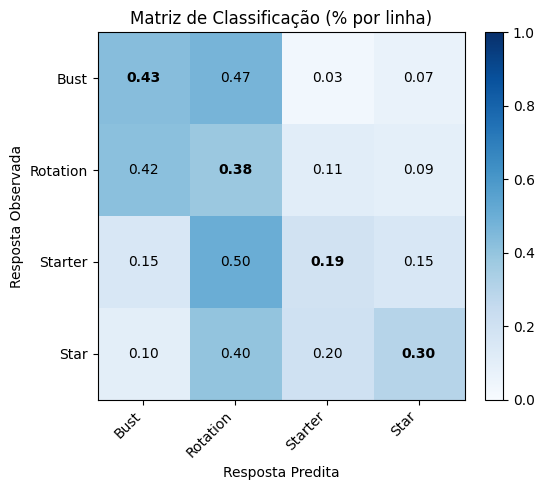

In [53]:
# Gráfico de calor com frequências relativas, somando 100% em cada linha
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_linhas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_linhas.shape[1]))
ax.set_yticks(range(tabela_relativa_linhas.shape[0]))
ax.set_xticklabels(tabela_relativa_linhas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_linhas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por linha)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [54]:

# 1. Acurácia e Relatório Padrão
acuracia = accuracy_score(resultados_teste['Real'], resultados_teste['Previsto'])
print(f'Acurácia Global: {acuracia:.3f}\n')

print("Relatório de Classificação Padrão:")
print(classification_report(resultados_teste['Real'], resultados_teste['Previsto'], labels=ordem_categorias))

# 2. Matriz de Confusão (Usando os labels para garantir a ordem correta)
conf_matrix = confusion_matrix(resultados_teste['Real'], 
                               resultados_teste['Previsto'], 
                               labels=ordem_categorias)

# Cálculos de matriz (One-vs-Rest)
TP = np.diag(conf_matrix)
FP = conf_matrix.sum(axis=0) - TP
FN = conf_matrix.sum(axis=1) - TP
TN = conf_matrix.sum() - (FP + FN + TP)

# Fórmulas de Performance
sensibilidade = TP / (TP + FN)  # Recall
especificidade = TN / (TN + FP)
ppv = TP / (TP + FP)            # Precision
npv = TN / (TN + FN)

tabela_metricas_completas = pd.DataFrame({
    'Sensibilidade (Recall)': sensibilidade,
    'Especificidade': especificidade,
    'Precisão (PPV)': ppv,
    'NPV': npv
}, index=ordem_categorias)

display(tabela_metricas_completas.round(3))

Acurácia Global: 0.377

Relatório de Classificação Padrão:
              precision    recall  f1-score   support

        Bust       0.61      0.43      0.50       100
    Rotation       0.25      0.38      0.30        55
     Starter       0.31      0.19      0.24        26
        Star       0.16      0.30      0.21        10

    accuracy                           0.38       191
   macro avg       0.33      0.33      0.31       191
weighted avg       0.44      0.38      0.39       191



,Sensibilidade (Recall),Especificidade,Precisão (PPV),NPV
Bust,0.430,0.692,0.606,0.525
Rotation,0.382,0.529,0.247,0.679
Starter,0.192,0.933,0.312,0.880
Star,0.300,0.912,0.158,0.959
